In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

engine = create_engine("postgresql+psycopg://localhost/phillies")

# Chart colors: primary series, comparison, neutral
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "lines.linewidth": 2,
})

TEST_SEASON = 2026
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

ModuleNotFoundError: No module named 'numpy'

In [2]:
query = """
select
    f.*,
    o.team_name, o.league, o.division, o.is_division_rival,
    d.day_name, d.day_of_week, d.month, d.month_name, d.is_weekend
from analytics.fct_home_games f
join analytics.dim_opponent o using (opponent)
join analytics.dim_date d on d.date_day = f.game_date
order by f.game_date, f.game_number
"""
df = pd.read_sql(query, engine, parse_dates=["game_date"])

# Postgres numeric columns arrive as Decimal objects; convert to floats
numeric_cols = [
    "pregame_win_pct", "pregame_games_behind", "pregame_leverage", "last10_win_pct",
    "game_temp_f", "game_precip_in", "game_wind_mph", "game_humidity_pct", "game_cloud_cover_pct",
]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c])

df["had_rain"] = df["had_rain"].astype("boolean")
df["day_name"] = df["day_name"].str.strip()
df["month_name"] = df["month_name"].str.strip()
df["game_time"] = np.where(df["is_night"], "Night", "Day")

train = df[df["season"] < TEST_SEASON].copy()
test = df[df["season"] == TEST_SEASON].copy()

print(f"All games: {len(df)} | 2015-2025 (explore): {len(train)} | 2026 (holdout): {len(test)}")
df.head()

All games: 792 | 2015-2025 (explore): 712 | 2026 (holdout): 80


,game_id,game_date,opponent,season,game_number,is_night,is_home_opener,is_doubleheader,is_single_admission_dh,home_game_seq,pregame_wins,pregame_losses,pregame_win_pct,pregame_games_behind,pregame_division_rank,pregame_streak,pregame_leverage,last10_win_pct,rolling5_attendance,game_temp_f,game_precip_in,game_wind_mph,game_humidity_pct,game_cloud_cover_pct,had_rain,is_win,runs_scored,runs_allowed,duration_minutes,attendance,team_name,league,division,is_division_rival,day_name,day_of_week,month,month_name,is_weekend,game_time
0,2015-0406-1,2015-04-06,BOS,2015,1,False,True,False,False,1,0,0,NaN,NaN,NaN,0,NaN,NaN,NaN,69.50,0.00,11.00,37.00,6.00,False,False,0,8,181,45549,Boston Red Sox,AL,AL East,False,Mon,1,4,Apr,False,Day
1,2015-0408-1,2015-04-08,BOS,2015,1,True,False,False,False,2,0,1,0.00,1.00,3.00,-1,0.88,0.00,"45,549.00",41.30,0.00,8.10,78.00,100.00,False,True,4,2,174,26465,Boston Red Sox,AL,AL East,False,Wed,3,4,Apr,False,Night
2,2015-0409-1,2015-04-09,BOS,2015,1,True,False,False,False,3,1,1,0.50,1.50,2.00,1,0.88,0.50,"36,007.00",41.30,0.00,7.50,81.00,100.00,False,False,2,6,188,23418,Boston Red Sox,AL,AL East,False,Thu,4,4,Apr,False,Night
3,2015-0410-1,2015-04-10,WSN,2015,1,True,False,False,False,4,1,2,0.33,2.00,3.00,-1,0.89,0.33,"31,811.00",58.90,0.00,6.80,96.00,100.00,False,True,4,1,150,19047,Washington Nationals,NL,NL East,True,Fri,5,4,Apr,False,Night
4,2015-0411-1,2015-04-11,WSN,2015,1,True,False,False,False,5,2,2,0.50,2.00,2.00,1,1.01,0.50,"28,620.00",50.70,0.00,4.50,45.00,0.00,False,True,3,2,205,23740,Washington Nationals,NL,NL East,True,Sat,6,4,Apr,True,Night


In [3]:
assert df["game_id"].is_unique, "duplicate game_id"
assert df["attendance"].notna().all(), "missing attendance"

nulls = df.isna().sum()
print("Columns with nulls:")
print(nulls[nulls > 0].to_string())

(
    df.groupby("season")
      .agg(home_games=("game_id", "count"),
           avg_att=("attendance", "mean"),
           min_att=("attendance", "min"),
           max_att=("attendance", "max"),
           night_share=("is_night", "mean"))
      .round({"avg_att": 0, "night_share": 2})
)

Columns with nulls:
pregame_win_pct           5
pregame_games_behind      5
pregame_division_rank     5
pregame_leverage          5
last10_win_pct            5
rolling5_attendance      10


,home_games,avg_att,min_att,max_att,night_share
season,,,,,
2015,77,"23,498.00",13238,45549,0.73
2016,80,"23,478.00",15247,45229,0.70
2017,78,"24,097.00",15154,45121,0.67
2018,77,"27,552.00",17050,44488,0.71
2019,80,"33,695.00",23243,44722,0.70
2022,80,"28,459.00",17145,44232,0.68
2023,80,"38,158.00",27025,44669,0.62
2024,80,"41,358.00",28077,44786,0.69
2025,80,"41,660.00",32314,45079,0.68


**Findings: data quality**
- 792 home games total: 712 in 2015 to 2025 (explore) and 80 in 2026 (holdout). No duplicate `game_id`s and no missing attendance.
- Nulls are all expected: 5 games with no `pregame_*` values are season openers played at home (no standing exists before game 1), and `rolling5_attendance` is null for the first home game of each season.
- Seasons have 77 to 80 home games. Shortfalls come from single-admission doubleheaders merged into one row, unplayed games, and the 2024 London game excluded as a neutral site.
- Night games are 62% to 73% of the home schedule every season, so the schedule mix is stable year to year.

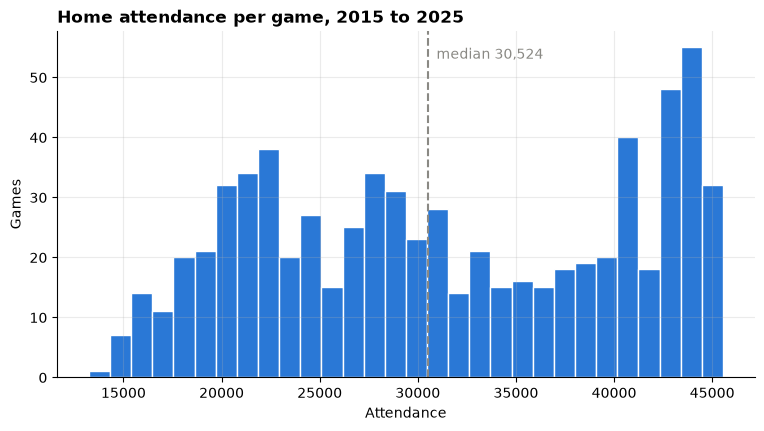

count      712.00
mean    31,398.00
std      9,131.00
min     13,238.00
25%     22,988.00
50%     30,524.00
75%     40,538.00
max     45,549.00
Name: attendance, dtype: float64

In [4]:
med = train["attendance"].median()

fig, ax = plt.subplots()
ax.hist(train["attendance"], bins=30, color=BLUE, edgecolor="white")
ax.axvline(med, color=GRAY, linestyle="--", linewidth=1.5)
ax.annotate(f"median {med:,.0f}", xy=(med, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", color=GRAY)
ax.set_title("Home attendance per game, 2015 to 2025")
ax.set_xlabel("Attendance")
ax.set_ylabel("Games")
plt.show()

train["attendance"].describe().round(0)

**Findings: attendance distribution**
- Mean 31,398, median 30,524, standard deviation 9,131. Range 13,238 to 45,549.
- The distribution is **bimodal**: one cluster around 20,000 to 23,000 and a second, taller cluster at 42,000 to 45,000. That matches two eras (rebuilding years vs. contending years) rather than one stable demand level.
- The upper cluster stops sharply around 45,000, which is effectively Citizens Bank Park's capacity. Many recent games are sellouts, so attendance is **capped**: a model cannot predict above capacity, and demand above it is invisible in the data.

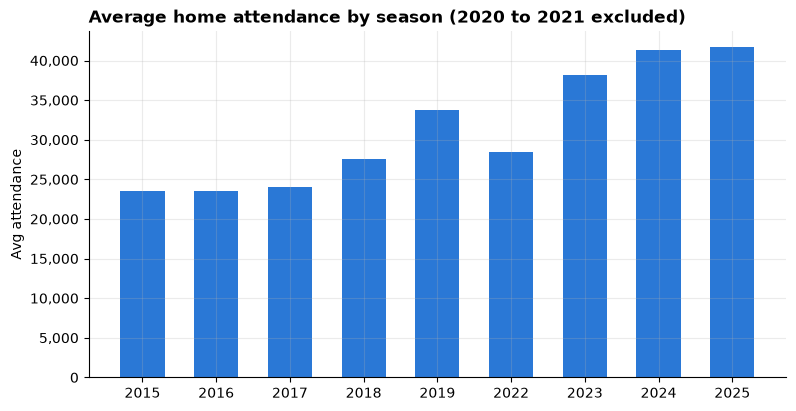

season
2015   23,498.00
2016   23,478.00
2017   24,097.00
2018   27,552.00
2019   33,695.00
2022   28,459.00
2023   38,158.00
2024   41,358.00
2025   41,660.00
Name: attendance, dtype: float64

In [7]:
season_att = train.groupby("season")["attendance"].mean()

fig, ax = plt.subplots()
ax.bar(season_att.index.astype(str), season_att.values, color=BLUE, width=0.6)
ax.set_title("Average home attendance by season (2020 to 2021 excluded)")
ax.set_ylabel("Avg attendance")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
plt.show()

season_att.round(0)

**Findings: season trend**
- Attendance roughly held at 23,500 to 24,100 from 2015 to 2017, then climbed to 27,552 (2018) and 33,695 (2019).
- 2022 dropped back to 28,459 despite a winning team, likely post-pandemic recovery in the first full season back.
- Attendance then surged to 38,158 (2023), 41,358 (2024), and 41,660 (2025), nearly double the 2015 to 2017 level.
- Most of the variation in attendance is **between seasons**, not between games within a season. The model needs features that capture season-level demand.

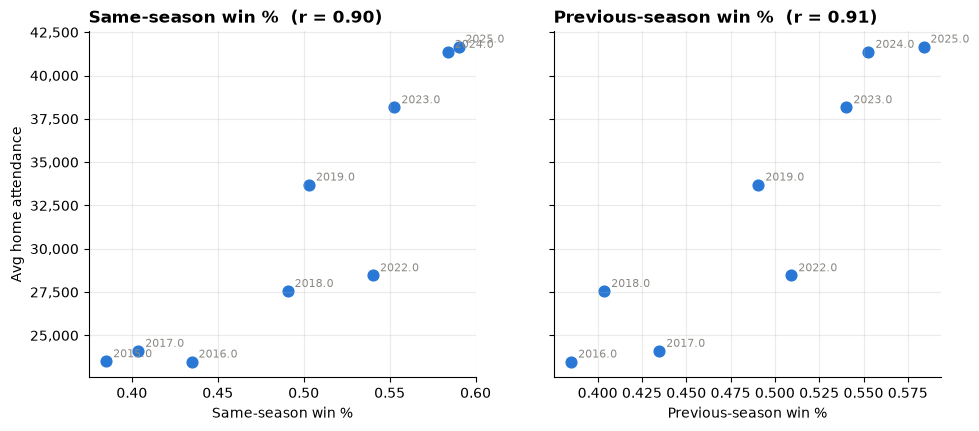

,season,wins,losses,win_pct,prev_win_pct,avg_att
0,2015,62,99,0.39,NaN,"23,498.00"
1,2016,70,91,0.43,0.39,"23,477.61"
2,2017,65,96,0.40,0.43,"24,097.44"
3,2018,79,82,0.49,0.40,"27,551.86"
4,2019,81,80,0.50,0.49,"33,695.20"
5,2022,87,74,0.54,0.51,"28,459.20"
6,2023,89,72,0.55,0.54,"38,157.56"
7,2024,94,67,0.58,0.55,"41,357.97"
8,2025,95,66,0.59,0.58,"41,660.25"


In [8]:
# Full-season record (home + away) from staging
records = pd.read_sql(
    """
    select season, max(wins_to_date) as wins, max(losses_to_date) as losses
    from analytics.stg_games
    group by season order by season
    """,
    engine,
)
records["win_pct"] = records["wins"] / (records["wins"] + records["losses"])
records["prev_win_pct"] = records["win_pct"].shift(1)  # last season's record

seasons = records.merge(season_att.rename("avg_att").reset_index(), on="season")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, col, title in [
    (axes[0], "win_pct", "Same-season win %"),
    (axes[1], "prev_win_pct", "Previous-season win %"),
]:
    ax.scatter(seasons[col], seasons["avg_att"], s=60, color=BLUE)
    for _, row in seasons.iterrows():
        ax.annotate(str(row["season"]), (row[col], row["avg_att"]), xytext=(5, 3),
                    textcoords="offset points", fontsize=8, color=GRAY)
    r = seasons[[col, "avg_att"]].corr().iloc[0, 1]
    ax.set_title(f"{title}  (r = {r:.2f})")
    ax.set_xlabel(title)
axes[0].set_ylabel("Avg home attendance")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
plt.show()

seasons.round(3)

**Findings: team quality and season demand**
- Season attendance tracks team quality very closely: r = 0.90 with same-season win % and r = 0.91 with previous-season win %.
- With only 9 seasons the two are effectively tied, so this can't settle which matters more. Both rise together because the team improved steadily from 2015 (.385) to 2025 (.590).
- 2022 is the clear outlier in both charts: a .540 team drawing only 28,459, consistent with a post-pandemic dip.
- Previous-season win % is a useful model feature because it is known before the season starts, when most tickets are sold.
- Chart note: season labels show as `2015.0` because the merge turned `season` into a float. Use `str(int(row["season"]))` in the annotation to fix it.

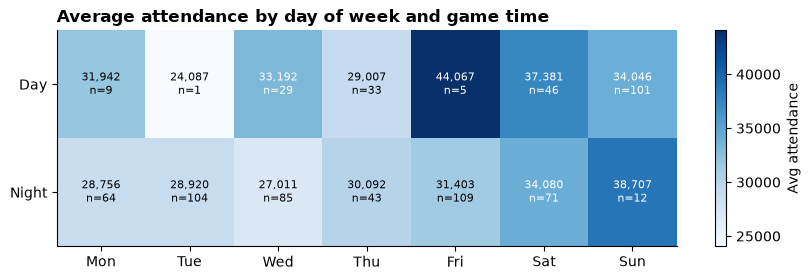

In [9]:
def heatmap(values, counts, title):
    fig, ax = plt.subplots(figsize=(10, 2.8))
    im = ax.imshow(values.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(values.shape[1]), values.columns)
    ax.set_yticks(range(values.shape[0]), values.index)
    ax.grid(False)
    threshold = np.nanmean(values.values)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values.values[i, j]
            if np.isnan(v):
                continue
            ax.text(j, i, f"{v:,.0f}\nn={int(counts.values[i, j])}", ha="center", va="center",
                    fontsize=8, color="white" if v > threshold else "black")
    fig.colorbar(im, ax=ax, label="Avg attendance")
    ax.set_title(title)
    plt.show()


avg = train.pivot_table(index="game_time", columns="day_name", values="attendance", aggfunc="mean").reindex(columns=DAYS)
n = train.pivot_table(index="game_time", columns="day_name", values="attendance", aggfunc="count").reindex(columns=DAYS)
heatmap(avg, n, "Average attendance by day of week and game time")

**Findings: day of week and game time**
- Weekends draw the most: Saturday day 37,381 (n=46), Sunday day 34,046 (n=101), Saturday night 34,080 (n=71).
- Weekday night games are the baseline at roughly 27,000 to 31,000, with Wednesday night lowest (27,011, n=85) and Friday night highest (31,403, n=109).
- Several cells have tiny samples and shouldn't be trusted: Tuesday day (n=1), Friday day (n=5), Monday day (n=9), Sunday night (n=12). Friday day's 44,067 is mostly home openers.
- Day games outdraw night games on most days, but day games cluster on weekends and openers, so this is partly a weekend effect. Use `is_weekend` and `is_night` together in the model rather than reading day vs. night alone.

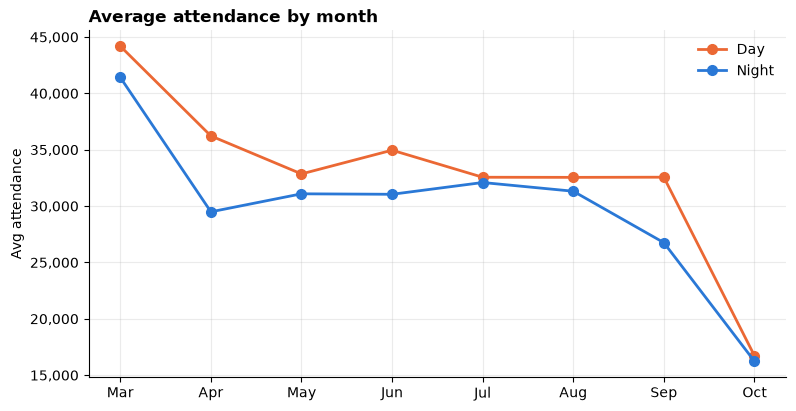

Home opener vs. other games:


,mean,count
is_home_opener,,
False,"31,227.00",703
True,"44,722.00",9


In [10]:
monthly = (
    train.groupby(["month", "month_name", "game_time"])["attendance"].mean()
         .unstack("game_time")
         .reset_index()
         .sort_values("month")
)

fig, ax = plt.subplots()
for col, color in [("Day", ORANGE), ("Night", BLUE)]:
    ax.plot(monthly["month_name"], monthly[col], marker="o", markersize=7, color=color, label=col)
ax.set_title("Average attendance by month")
ax.set_ylabel("Avg attendance")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(frameon=False)
plt.show()

print("Home opener vs. other games:")
train.groupby("is_home_opener")["attendance"].agg(["mean", "count"]).round(0)

**Findings: month and home opener**
- Home openers average **44,722** vs. 31,227 for all other games (+13,495, n=9). The opener is effectively a guaranteed sellout and needs its own flag in the model.
- March is high only because its few games are openers. Excluding that, attendance is flat at about 31,000 to 35,000 from April through August.
- September drops for night games (about 26,700) and October falls to about 16,000, when the team is often out of the race and school is back in session.
- Day games draw at least as many fans as night games in every month, with the biggest gap in April (about 36,000 vs. 29,500).

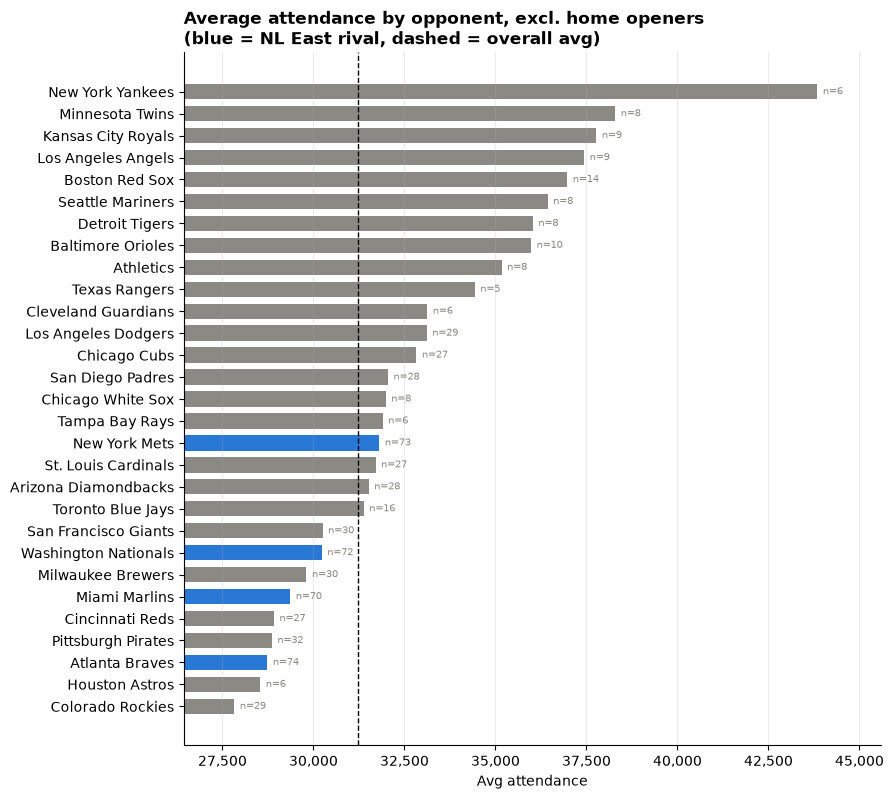

,mean,median,count
group,,,
AL (interleague),"35,247.00","38,331.00",127
NL East rival,"30,037.00","28,683.00",289
Other NL,"30,647.00","30,025.00",287


In [11]:
no_opener = train[~train["is_home_opener"]]

opp = (
    no_opener.groupby(["team_name", "is_division_rival"])["attendance"]
             .agg(avg="mean", games="count")
             .reset_index()
             .sort_values("avg")
)

fig, ax = plt.subplots(figsize=(9, 9))
colors = np.where(opp["is_division_rival"], BLUE, GRAY)
ax.barh(opp["team_name"], opp["avg"], color=colors, height=0.7)
for y, (v, g) in enumerate(zip(opp["avg"], opp["games"])):
    ax.text(v + 150, y, f"n={g}", va="center", fontsize=7, color=GRAY)
ax.axvline(no_opener["attendance"].mean(), color="black", linewidth=1, linestyle="--")
ax.set_xlim(opp["avg"].min() * 0.95, opp["avg"].max() * 1.04)
ax.set_title("Average attendance by opponent, excl. home openers\n(blue = NL East rival, dashed = overall avg)")
ax.set_xlabel("Avg attendance")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
plt.show()

(
    no_opener.assign(group=np.select(
        [no_opener["is_division_rival"], no_opener["league"] == "NL"],
        ["NL East rival", "Other NL"],
        default="AL (interleague)",
    ))
    .groupby("group")["attendance"].agg(["mean", "median", "count"]).round(0)
)

**Findings: opponent (excluding home openers)**
- **AL interleague** visitors draw the most: 35,247 average (n=127), vs. 30,647 for other NL teams (n=287) and 30,037 for NL East rivals (n=289).
- The Yankees lead at about 43,800 but with only 6 games. The Red Sox (n=14) and several AL teams with 8 to 10 games also sit well above average.
- NL East rivals are **not** a draw: the Mets are slightly above average (n=73), while the Nationals, Marlins, and Braves are below it.
- Caution: since the 2023 balanced schedule, every AL team visits more often, so AL games are concentrated in the high-attendance 2023 to 2025 seasons. Part of the AL premium is a season effect.
- Most teams have fewer than 10 games, too few for reliable per-team estimates. For modeling, use grouped opponent features (NL East / other NL / AL) plus possibly a marquee flag, not 29 team dummies.

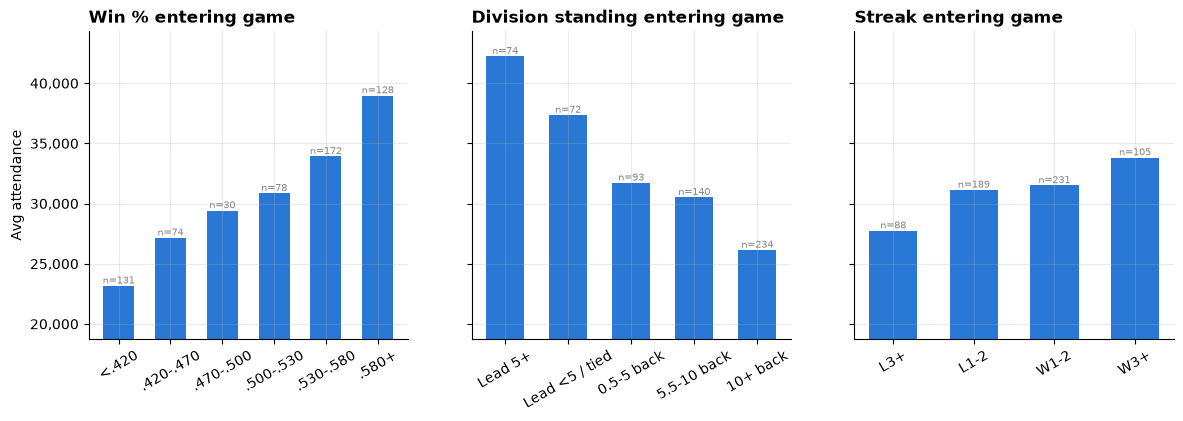

In [12]:
# Skip each season's first ~20 games: win % is too noisy that early
settled = train[(train["pregame_wins"] + train["pregame_losses"]) >= 20].copy()

settled["win_pct_band"] = pd.cut(
    settled["pregame_win_pct"], [0, 0.42, 0.47, 0.50, 0.53, 0.58, 1],
    labels=["<.420", ".420-.470", ".470-.500", ".500-.530", ".530-.580", ".580+"],
)
settled["gb_band"] = pd.cut(
    settled["pregame_games_behind"], [-np.inf, -5, 0, 5, 10, np.inf],
    labels=["Lead 5+", "Lead <5 / tied", "0.5-5 back", "5.5-10 back", "10+ back"],
)
settled["streak_band"] = pd.cut(
    settled["pregame_streak"], [-np.inf, -3, -1, 0, 2, np.inf],
    labels=["L3+", "L1-2", "None", "W1-2", "W3+"],
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, col, title in [
    (axes[0], "win_pct_band", "Win % entering game"),
    (axes[1], "gb_band", "Division standing entering game"),
    (axes[2], "streak_band", "Streak entering game"),
]:
    g = settled.groupby(col, observed=True)["attendance"].agg(["mean", "count"])
    ax.bar(g.index.astype(str), g["mean"], color=BLUE, width=0.6)
    for x, (m, c) in enumerate(zip(g["mean"], g["count"])):
        ax.text(x, m, f"n={c}", ha="center", va="bottom", fontsize=7, color=GRAY)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Avg attendance")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
axes[0].set_ylim(settled["attendance"].mean() * 0.6, None)
plt.show()

**Findings: in-season team performance (after each season's first 20 games)**
- Attendance rises steadily with win % entering the game: about 23,200 under .420 up to about 38,900 at .580+.
- Division standing shows the strongest pattern: about 42,300 when leading by 5+ games down to about 26,200 when 10+ games back.
- Streaks matter much less: about 27,700 after 3+ straight losses vs. about 33,800 after 3+ straight wins, with little difference between short streaks.
- These are confounded with season, since the best records all come from the 2022 to 2025 surge years. The model has to separate season-level demand from in-season form.

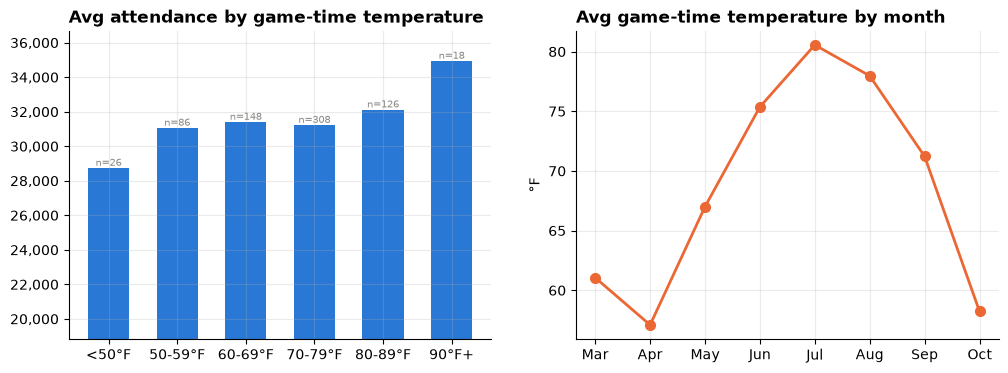

Rain during game vs. not:


,mean,count
had_rain,,
False,"31,359.00",677
True,"32,144.00",35


In [13]:
bands = [-np.inf, 50, 60, 70, 80, 90, np.inf]
labels = ["<50°F", "50-59°F", "60-69°F", "70-79°F", "80-89°F", "90°F+"]
wx = train.assign(temp_band=pd.cut(train["game_temp_f"], bands, labels=labels, right=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: attendance by temperature band
g = wx.groupby("temp_band", observed=True)["attendance"].agg(["mean", "count"])
axes[0].bar(g.index.astype(str), g["mean"], color=BLUE, width=0.6)
for x, (m, c) in enumerate(zip(g["mean"], g["count"])):
    axes[0].text(x, m, f"n={c}", ha="center", va="bottom", fontsize=7, color=GRAY)
axes[0].set_title("Avg attendance by game-time temperature")
axes[0].set_ylim(wx["attendance"].mean() * 0.6, None)
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")

# Right: confounding check, temperature by month
t = wx.groupby(["month", "month_name"])["game_temp_f"].mean().reset_index().sort_values("month")
axes[1].plot(t["month_name"], t["game_temp_f"], marker="o", markersize=7, color=ORANGE)
axes[1].set_title("Avg game-time temperature by month")
axes[1].set_ylabel("°F")
plt.show()

print("Rain during game vs. not:")
train.groupby("had_rain")["attendance"].agg(["mean", "count"]).round(0)

**Findings: weather**
- Temperature barely matters between 50°F and 89°F (about 31,000 to 32,000 in every band).
- Cold games under 50°F draw less (about 28,700, n=26), and 90°F+ games draw more (about 34,900, n=18). Both groups are small.
- Temperature tracks the calendar closely (coldest in April at about 57°F, warmest in July at about 80°F), so cold games are mostly early-season games. Temperature and month need to be modeled together.
- Rain during the game shows **no** penalty (32,144 with rain vs. 31,359 without). This uses actual weather, and games that were rained out entirely aren't in the data, so any rain effect is understated. Fans buy tickets on the forecast, not the actual weather.

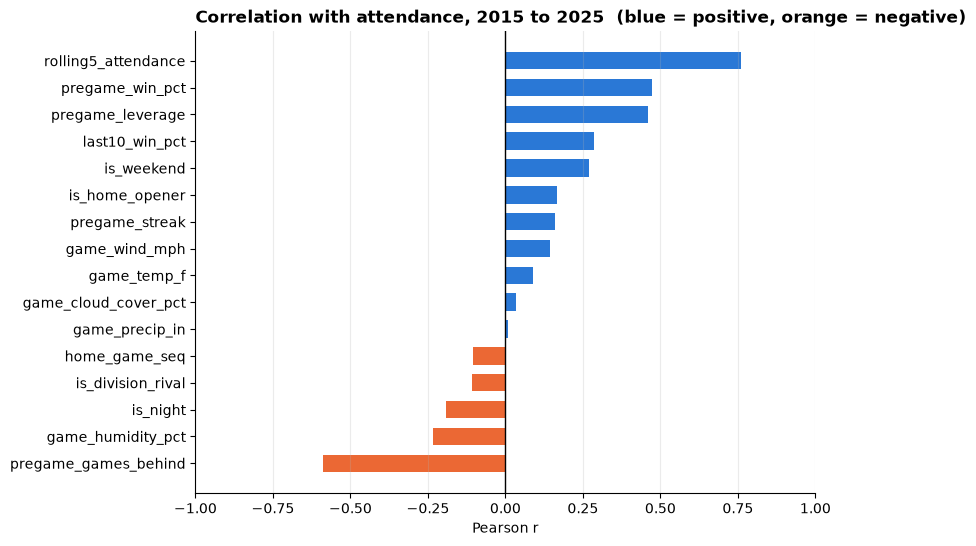

pregame_games_behind   -0.59
game_humidity_pct      -0.23
is_night               -0.19
is_division_rival      -0.11
home_game_seq          -0.10
game_precip_in          0.01
game_cloud_cover_pct    0.03
game_temp_f             0.09
game_wind_mph           0.14
pregame_streak          0.16
is_home_opener          0.17
is_weekend              0.27
last10_win_pct          0.29
pregame_leverage        0.46
pregame_win_pct         0.47
rolling5_attendance     0.76
Name: attendance, dtype: float64

In [14]:
feature_cols = [
    "pregame_win_pct", "pregame_games_behind", "pregame_streak", "pregame_leverage",
    "last10_win_pct", "rolling5_attendance", "home_game_seq",
    "game_temp_f", "game_precip_in", "game_wind_mph", "game_humidity_pct", "game_cloud_cover_pct",
    "is_night", "is_weekend", "is_division_rival", "is_home_opener",
]
corr_df = train[feature_cols + ["attendance"]].astype(float)
corr = corr_df.corr()["attendance"].drop("attendance").sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr.index, corr.values, color=np.where(corr.values >= 0, BLUE, ORANGE), height=0.65)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlim(-1, 1)
ax.set_title("Correlation with attendance, 2015 to 2025  (blue = positive, orange = negative)")
ax.set_xlabel("Pearson r")
ax.grid(axis="y", visible=False)
plt.show()

corr.round(3)

**Findings: correlation with attendance**
- Strongest: `rolling5_attendance` (r = 0.76), then `pregame_games_behind` (-0.59), `pregame_win_pct` (0.47), and `pregame_leverage` (0.46).
- Moderate: `last10_win_pct` (0.29), `is_weekend` (0.27), `is_home_opener` (0.17), `pregame_streak` (0.16).
- Weak or none: temperature (0.09), precipitation (0.01), cloud cover (0.03), wind (0.14).
- `game_humidity_pct` (-0.23) and `is_night` (-0.19) are negative, but both are likely confounded (humid nights are weeknights in summer), so treat them with caution.
- `rolling5_attendance` captures season-level demand directly. It is valid pregame information but will dominate a model, so compare models with and without it.

In [ ]:
# Spot redundant feature pairs before modeling
m = corr_df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(m)), m.columns, rotation=90)
ax.set_yticks(range(len(m)), m.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Feature correlation matrix, 2015 to 2025")
plt.show()

pairs = (
    m.where(np.triu(np.ones(m.shape, dtype=bool), k=1))
     .stack().rename("r").reset_index()
     .assign(abs_r=lambda d: d["r"].abs())
     .sort_values("abs_r", ascending=False)
)
pairs.head(10)

**Findings: redundant feature pairs**
- _Run the cell above, then list pairs with |r| above about 0.7 and which feature of each pair to keep._

## First look at 2026 (holdout, descriptive only)

Nothing in this section should change feature or model choices. It's context for interpreting the forecast later.

,home_games,avg_att,night_share,weekend_share,avg_temp,win_pct,prev_win_pct
season,,,,,,,
2025,80,"41,660.25",0.68,0.34,71.52,0.59,0.58
2026,80,"39,854.75",0.71,0.31,73.37,0.54,0.59


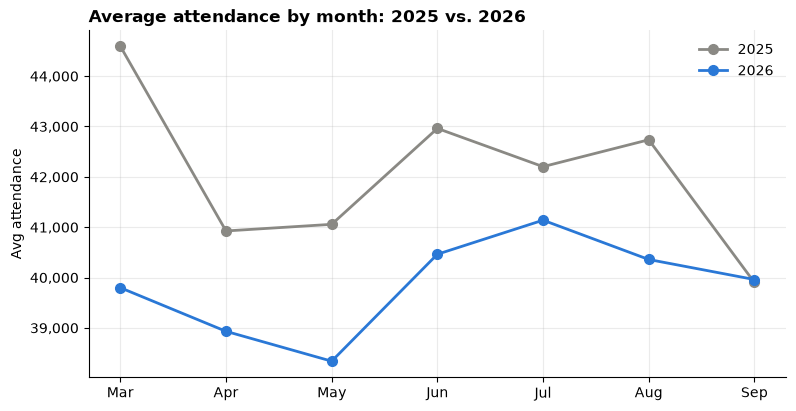

In [17]:
cmp = df[df["season"].isin([2025, TEST_SEASON])]

summary = (
    cmp.groupby("season")
       .agg(home_games=("game_id", "count"),
            avg_att=("attendance", "mean"),
            night_share=("is_night", "mean"),
            weekend_share=("is_weekend", "mean"),
            avg_temp=("game_temp_f", "mean"))
       .join(records.set_index("season")[["win_pct", "prev_win_pct"]])
)
display(summary.round(3))

by_month = (
    cmp.groupby(["season", "month", "month_name"])["attendance"].mean()
       .reset_index().sort_values("month")
)

fig, ax = plt.subplots()
for season, color in [(2025, GRAY), (TEST_SEASON, BLUE)]:
    s = by_month[by_month["season"] == season]
    ax.plot(s["month_name"], s["attendance"], marker="o", markersize=7, color=color, label=str(season))
ax.set_title("Average attendance by month: 2025 vs. 2026")
ax.set_ylabel("Avg attendance")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(frameon=False)
plt.show()

**Findings: 2026 (descriptive only)**
- 2026 averaged **39,855**, down 1,806 per game (about 4%) from 2025's 41,660.
- The drop shows up in nearly every month: largest in March (about 39,800 vs. 44,600) and April to May (2,000 to 2,700 lower), smaller in summer, and September was even (about 40,000 both years).
- The schedule mix was similar: 71% night games vs. 68%, 31% weekend vs. 34%, and slightly warmer weather.
- The team was weaker: .540 in 2026 vs. .590 in 2025. Previous-season win % was the best ever (.590), so last year's success alone did not hold attendance up. In-season performance and a slightly lighter weekend schedule are the most likely explanations.
- The 2026 forecast test will show whether the model's features capture this dip.

## Summary for modeling

1. **Strongest drivers:** season-level demand (team quality this year and last year; recent crowds via `rolling5_attendance`), division standing, home opener, and weekends.
2. **Weak or no effect:** temperature between 50°F and 89°F, rain during the game, cloud cover, wind, and streaks beyond their link to overall record.
3. **Confounders to handle:** temperature vs. month; win % and standing vs. season (good records only exist in the surge years); AL opponents vs. season (balanced schedule since 2023); day vs. night vs. weekend.
4. **Features to engineer or group:** `is_home_opener` flag, `prev_season_win_pct`, opponent groups (NL East / other NL / AL), cold-game flag (under 50°F), weekend and night flags together.
5. **Redundant pairs to drop one of:** _fill in from the feature correlation matrix._
6. **Data caveats:** attendance is capped at capacity (sellouts hide true demand); weather is actual, not forecast; rained-out games aren't in the data; most opponents have small samples; 2022 is a post-pandemic outlier; 2026 has no Retrosheet venue check yet.